# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [2]:
# TODO 1: one 1080p RGB frame, in MB
W, H, C, B = 1920, 1080, 3, 8
frame_bytes = W * H * C * (B // 8)
frame_mb = frame_bytes / (1024 ** 2)

# TODO 2: frames per camera per day at 30 fps
frames_per_day = 30 * 24 * 60 * 60

# TODO 3: 400 cameras x 24 h, uncompressed, in TB
fleet_bytes = frame_bytes * frames_per_day * 400
fleet_tb = fleet_bytes / (1024 ** 4)

# TODO 4: same fleet at 640x360 and 10 fps
small_W, small_H, small_fps = 640, 360, 10
small_frame_bytes = small_W * small_H * 3
small_frames_per_day = small_fps * 24 * 60 * 60

fleet_tb_small = (
    small_frame_bytes * small_frames_per_day * 400
) / (1024 ** 4)

pct_pixels_remaining = (
    (small_W * small_H) / (W * H)
) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | "
      f"Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: "
      f"{pct_pixels_remaining:.2f}%")

One frame: 5.93 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37
(raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal**
piece of evidence the security team could lose forever by making that choice.

_Your answer:_

The spatial evidence that could be lost is small visual details, such as a person's facial features, clothing, or a small object in their hand, because downsampling removes pixels and can make these details indistinguishable. The temporal evidence that could be lost is a brief action occurring between sampled frames, such as a person quickly picking up an object or making a sudden movement. Reducing the frame rate from 30 fps to 10 fps means that fewer moments are recorded, so short events may disappear from the footage entirely.

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

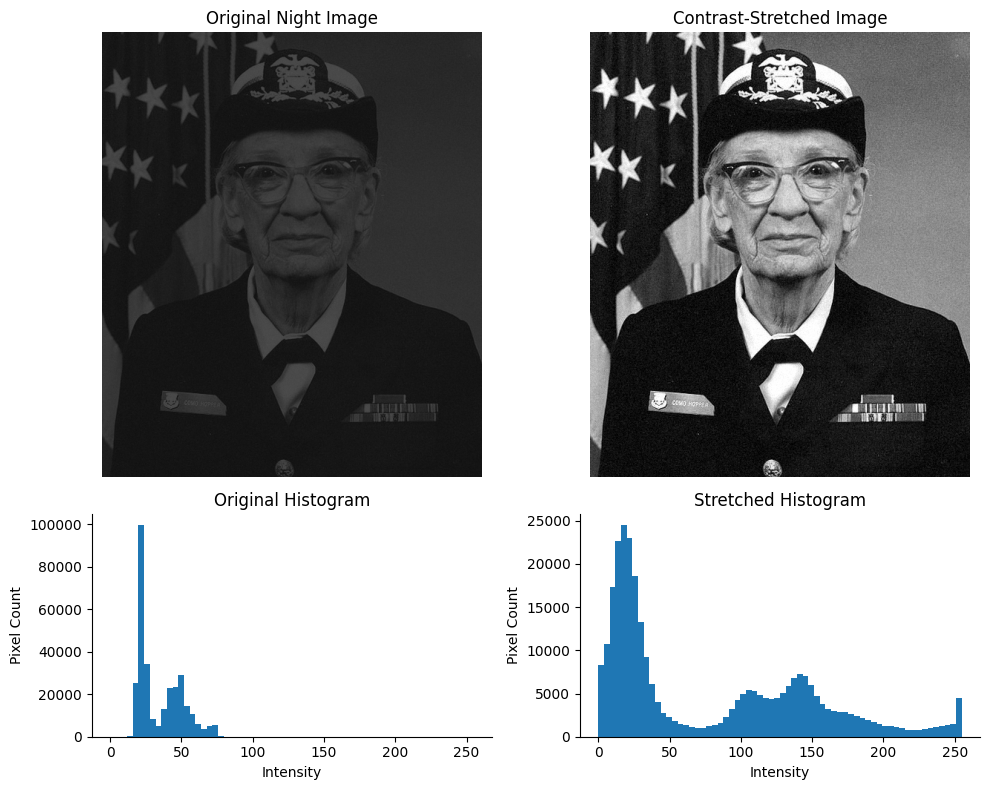

Contrast before: 0.609 -> after: 1.000


In [3]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# TODO 2: robust Michelson contrast of night_still
p1 = np.percentile(night_still, 1)
p99 = np.percentile(night_still, 99)

c_before = michelson(p99, p1)

# TODO 3: contrast-stretched version of night_still
stretched = np.clip(
    (night_still - p1) / (p99 - p1) * 255,
    0,
    255
)

p1_after = np.percentile(stretched, 1)
p99_after = np.percentile(stretched, 99)
c_after = michelson(p99_after, p1_after)

# TODO 1 & 4: images and histograms
fig, axes = plt.subplots(
    2, 2, figsize=(10, 8),
    gridspec_kw={"height_ratios": [2, 1]}
)

axes[0, 0].imshow(night_still, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Original Night Image")
axes[0, 0].axis("off")

axes[1, 0].hist(
    night_still.ravel(), bins=64, range=(0, 255)
)
axes[1, 0].set_title("Original Histogram")
axes[1, 0].set_xlabel("Intensity")
axes[1, 0].set_ylabel("Pixel Count")

axes[0, 1].imshow(stretched, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("Contrast-Stretched Image")
axes[0, 1].axis("off")

axes[1, 1].hist(
    stretched.ravel(), bins=64, range=(0, 255)
)
axes[1, 1].set_title("Stretched Histogram")
axes[1, 1].set_xlabel("Intensity")
axes[1, 1].set_ylabel("Pixel Count")

plt.tight_layout()
plt.show()

print(f"Contrast before: {c_before:.3f} -> after: {c_after:.3f}")

**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table).
Then explain why stretching made the image readable even though it added **no new information** — and why a
histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

_Your answer:_

The original night image has a narrow histogram concentrated toward the darker intensity values, indicating low contrast and poor visibility. Contrast stretching expands the occupied intensity range toward 0–255, making differences between dark and bright regions easier to see. However, it does not create new information because it only remaps the existing pixel intensities and cannot recover details that were never captured. A histogram shows the distribution and frequency of intensities but not their spatial arrangement, so two completely different images can have the same histogram.

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).


Standing time ranges:
68.70 s - 68.70 s
68.77 s - 68.77 s
68.87 s - 70.53 s
70.60 s - 70.83 s
70.90 s - 71.13 s
71.20 s - 71.63 s
71.70 s - 72.03 s
72.10 s - 72.13 s
72.23 s - 72.73 s
72.80 s - 73.23 s
73.30 s - 73.73 s
73.80 s - 73.90 s
73.97 s - 74.03 s
74.10 s - 74.23 s
74.30 s - 74.67 s
74.73 s - 75.37 s
75.43 s - 75.47 s
75.53 s - 75.57 s
75.63 s - 75.67 s
75.73 s - 75.73 s
75.80 s - 75.90 s
75.97 s - 76.53 s
76.63 s - 76.93 s
77.00 s - 78.10 s

Running time ranges:
78.60 s - 86.00 s

Audio event: frame 2250, time 75.00 s
Lighting event: frame 3000, time 100.00 s


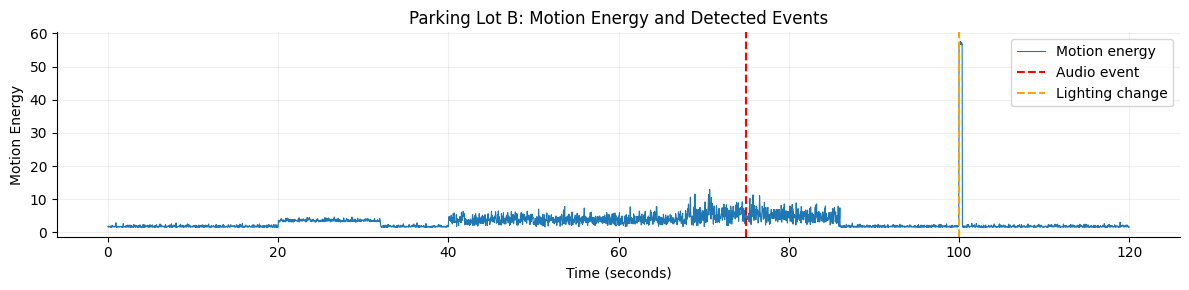

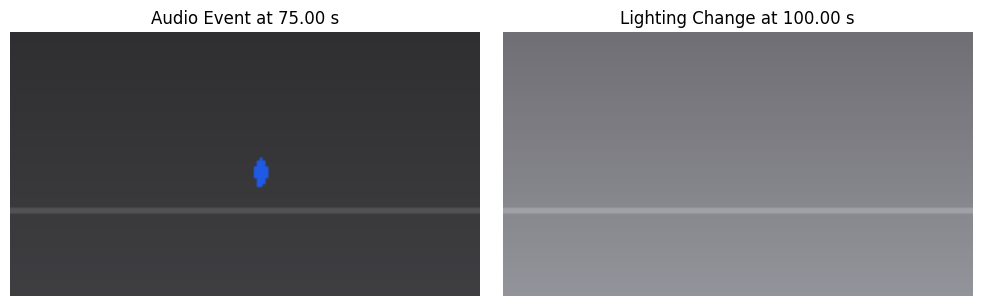

In [4]:
# TODO 1: person speed (px/s)
# Use a 30-frame difference, corresponding to approximately one second.
dx = cctv["person_x"].diff(FPS)
dy = cctv["person_y"].diff(FPS)

speed = np.sqrt(dx**2 + dy**2)

# TODO 2: standing / running time ranges
def print_time_ranges(mask, label):
    mask = mask.fillna(False).to_numpy()
    indices = np.flatnonzero(mask)

    print(f"\n{label} time ranges:")

    if len(indices) == 0:
        print("No matching ranges found.")
        return

    splits = np.where(np.diff(indices) > 1)[0] + 1

    for group in np.split(indices, splits):
        start = cctv.iloc[group[0]]["time_s"]
        end = cctv.iloc[group[-1]]["time_s"]
        print(f"{start:.2f} s - {end:.2f} s")

print_time_ranges(speed < 3, "Standing")
print_time_ranges(speed > 25, "Running")

# TODO 3: event frame indices
audio_event_idx = cctv.index[
    cctv["audio_level_db"] > -20
][0]

brightness_jump = cctv["mean_brightness"].diff()
lighting_event_idx = cctv.index[
    brightness_jump > 40
][0]

audio_event_time = cctv.loc[audio_event_idx, "time_s"]
lighting_event_time = cctv.loc[lighting_event_idx, "time_s"]

print(f"\nAudio event: frame {audio_event_idx}, "
      f"time {audio_event_time:.2f} s")

print(f"Lighting event: frame {lighting_event_idx}, "
      f"time {lighting_event_time:.2f} s")

# TODO 4: annotated motion-energy timeline
fig, ax = plt.subplots(figsize=(12, 3))

ax.plot(
    cctv["time_s"], cctv["motion_energy"],
    linewidth=0.8, label="Motion energy"
)

ax.axvline(
    audio_event_time, color="red",
    linestyle="--", label="Audio event"
)

ax.axvline(
    lighting_event_time, color="orange",
    linestyle="--", label="Lighting change"
)

ax.set_title("Parking Lot B: Motion Energy and Detected Events")
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Motion Energy")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# TODO 5: one keyframe per event
fig, axes = plt.subplots(1, 2, figsize=(10, 3))

for ax, idx, title in [
    (axes[0], audio_event_idx, "Audio Event"),
    (axes[1], lighting_event_idx, "Lighting Change")
]:
    ax.imshow(render_frame(cctv.iloc[idx]))
    ax.set_title(f"{title} at {cctv.iloc[idx]['time_s']:.2f} s")
    ax.axis("off")

plt.tight_layout()
plt.show()

**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most
likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

_Your answer:_

Uniform keyframes taken every 20 seconds could miss brief events such as the sudden audio spike around 75 seconds or the rapid lighting change around 100 seconds, especially if they occur between sampled frames. These events may last only a short time and would not necessarily coincide with a regularly sampled frame. Instead, I used content-based keyframe selection, which chooses representative frames based on detected changes or activity in the footage. This approach is more suitable when important events are sparse and irregularly timed.

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

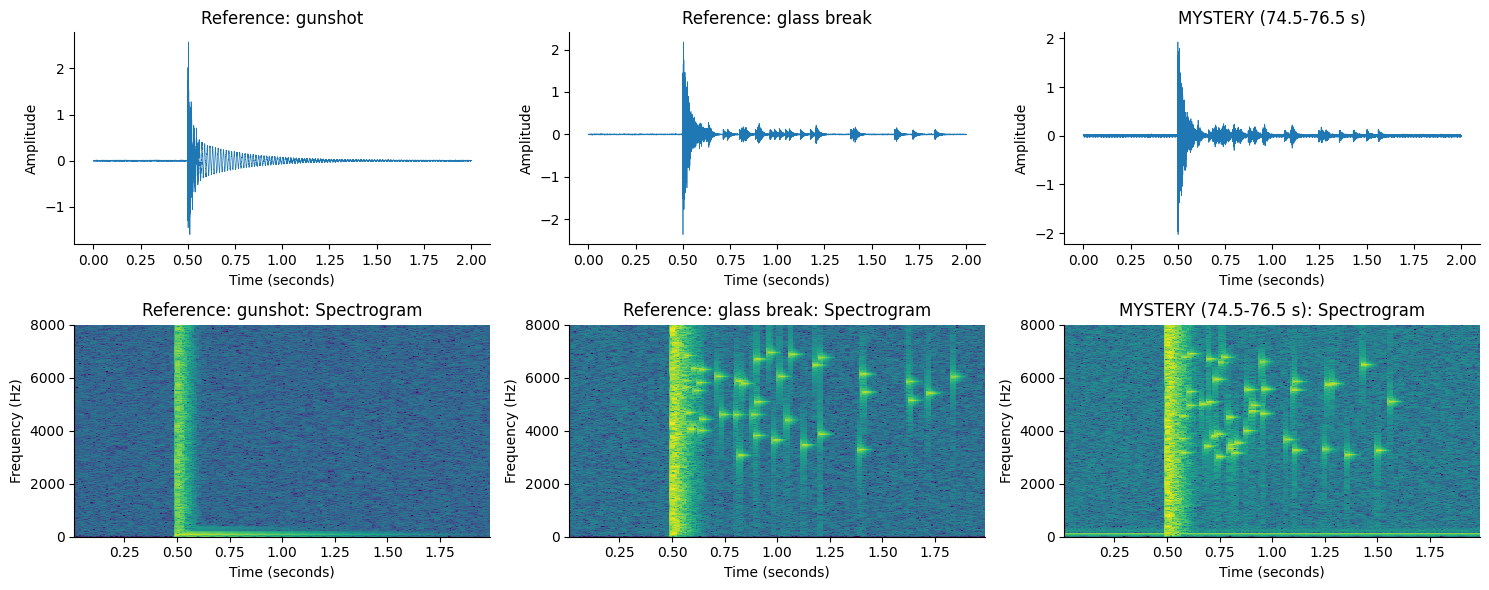

High-frequency energy fractions:
Reference: gunshot: 0.0030 (0.30%)
Reference: glass break: 0.9892 (98.92%)
MYSTERY (74.5-76.5 s): 0.8735 (87.35%)

VERDICT: The mystery sound is more consistent with breaking glass than with a gunshot.


In [5]:
mystery = x_audio[
    (t_audio >= 74.5) & (t_audio < 76.5)
]

clips = {
    "Reference: gunshot": ref_gunshot[1],
    "Reference: glass break": ref_glass[1],
    "MYSTERY (74.5-76.5 s)": mystery
}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))

# TODO 1 & 2: waveform and spectrogram for each clip
for col, (name, clip) in enumerate(clips.items()):
    t_clip = np.arange(len(clip)) / FS

    # Waveform
    axes[0, col].plot(t_clip, clip, linewidth=0.5)
    axes[0, col].set_title(name)
    axes[0, col].set_xlabel("Time (seconds)")
    axes[0, col].set_ylabel("Amplitude")

    # Spectrogram
    freqs, times, Sxx = signal.spectrogram(
        clip, fs=FS, nperseg=512, noverlap=384
    )

    Sxx_db = 10 * np.log10(Sxx + 1e-12)

    axes[1, col].pcolormesh(
        times, freqs, Sxx_db,
        shading="auto", cmap="viridis"
    )
    axes[1, col].set_ylim(0, 8000)
    axes[1, col].set_title(f"{name}: Spectrogram")
    axes[1, col].set_xlabel("Time (seconds)")
    axes[1, col].set_ylabel("Frequency (Hz)")

plt.tight_layout()
plt.show()

# TODO 3: fraction of spectral energy above 3 kHz,
# 0.2-1.2 seconds after the impact at 0.5 seconds.
hf_fraction = {}

for name, clip in clips.items():
    freqs, times, Sxx = signal.spectrogram(
        clip, fs=FS, nperseg=512, noverlap=384
    )

    time_mask = (times >= 0.7) & (times <= 1.7)
    high_mask = freqs > 3000

    selected_energy = Sxx[:, time_mask]

    total_energy = np.sum(selected_energy)
    high_energy = np.sum(selected_energy[high_mask, :])

    hf_fraction[name] = (
        high_energy / total_energy
        if total_energy > 0 else 0
    )

print("High-frequency energy fractions:")
for name, fraction in hf_fraction.items():
    print(f"{name}: {fraction:.4f} ({fraction * 100:.2f}%)")

# TODO 4: verdict
gunshot_fraction = hf_fraction["Reference: gunshot"]
glass_fraction = hf_fraction["Reference: glass break"]
mystery_fraction = hf_fraction["MYSTERY (74.5-76.5 s)"]

if abs(mystery_fraction - glass_fraction) < abs(
    mystery_fraction - gunshot_fraction
):
    print(
        "\nVERDICT: The mystery sound is more consistent with "
        "breaking glass than with a gunshot."
    )
else:
    print(
        "\nVERDICT: The mystery sound is more consistent with "
        "a gunshot than with breaking glass."
    )

**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass
break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern
(horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

_Your answer:_

No, the waveforms alone would not allow me to confidently distinguish a gunshot from breaking glass because both can produce a sudden, high-amplitude impact. The spectrogram adds three dimensions: time, frequency, and magnitude or energy, with magnitude represented by colour intensity. The gunshot reference has a sharp broadband impact followed by a decaying low-frequency boom, whereas the glass-break reference contains scattered high-frequency specks caused by lingering tinkling sounds. The mystery recording resembles the glass-break reference because it contains the characteristic scattered high-frequency energy after the initial impact.

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

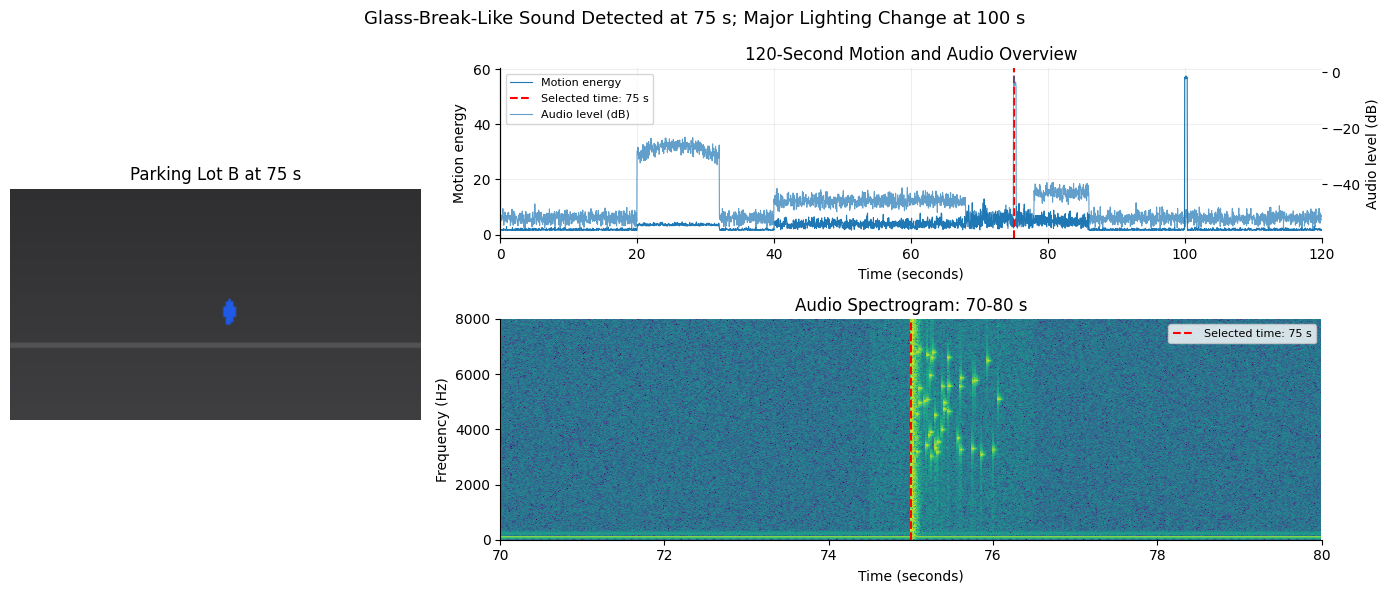

In [6]:
t_sel = 75.0

fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(
    2, 2,
    width_ratios=[1, 2],
    height_ratios=[1, 1.3]
)

# TODO 1: rendered video frame at t = 75 s
ax_frame = fig.add_subplot(gs[:, 0])

frame_idx = (
    (cctv["time_s"] - t_sel).abs()
).idxmin()

ax_frame.imshow(render_frame(cctv.iloc[frame_idx]))
ax_frame.set_title(f"Parking Lot B at {t_sel:.0f} s")
ax_frame.axis("off")

# TODO 2: full 120 s motion + audio timeline
ax_timeline = fig.add_subplot(gs[0, 1])

ax_timeline.plot(
    cctv["time_s"],
    cctv["motion_energy"],
    label="Motion energy",
    linewidth=0.8
)

ax_timeline.set_xlabel("Time (seconds)")
ax_timeline.set_ylabel("Motion energy")
ax_timeline.set_xlim(0, 120)

# Audio on a second y-axis
ax_audio = ax_timeline.twinx()

ax_audio.plot(
    cctv["time_s"],
    cctv["audio_level_db"],
    label="Audio level (dB)",
    alpha=0.7,
    linewidth=0.8
)

ax_audio.set_ylabel("Audio level (dB)")

ax_timeline.axvline(
    t_sel, color="red", linestyle="--",
    label="Selected time: 75 s"
)

lines1, labels1 = ax_timeline.get_legend_handles_labels()
lines2, labels2 = ax_audio.get_legend_handles_labels()

ax_timeline.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="upper left",
    fontsize=8
)

ax_timeline.set_title("120-Second Motion and Audio Overview")
ax_timeline.grid(alpha=0.2)

# TODO 3: spectrogram of audio from 70-80 s
ax_spec = fig.add_subplot(gs[1, 1])

freqs, times, Sxx = signal.spectrogram(
    x_audio, fs=FS, nperseg=512, noverlap=384
)

Sxx_db = 10 * np.log10(Sxx + 1e-12)

audio_times_absolute = times + 70

ax_spec.pcolormesh(
    audio_times_absolute,
    freqs,
    Sxx_db,
    shading="auto",
    cmap="viridis"
)

ax_spec.set_xlim(70, 80)
ax_spec.set_ylim(0, 8000)
ax_spec.set_xlabel("Time (seconds)")
ax_spec.set_ylabel("Frequency (Hz)")
ax_spec.set_title("Audio Spectrogram: 70-80 s")

# Same timestamp marker
ax_spec.axvline(
    t_sel, color="red", linestyle="--",
    label="Selected time: 75 s"
)
ax_spec.legend(loc="upper right", fontsize=8)

# TODO 4: conclusion-style title
fig.suptitle(
    "Glass-Break-Like Sound Detected at 75 s; "
    "Major Lighting Change at 100 s",
    fontsize=13
)

plt.tight_layout()
plt.show()

**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct
**synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video?
Which panel would make the mistake visible?

_Your answer:_

If the audio track were offset by +2 seconds, the sound would appear to occur two seconds later than its actual corresponding video event. This could lead the security team to associate the sound with the wrong action or person and draw an incorrect conclusion about what happened. The synchronized timeline panel would make the mismatch visible because the audio spike would no longer align with the video event at its true timestamp. Correct synchronization is essential for reliable multimodal analysis, while a cluttered display should be avoided to prevent information overload.

## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook.
It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view),
  using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes,
  time × frequency × magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.

_Your final briefing here:_


The Parking Lot B footage shows a person moving through the area between approximately 40 and 86 seconds, a glass-break-like sound at 75 seconds, and a major lighting change at 100 seconds. I recommend presenting the synchronized multimodal view first because it combines the video frame, motion and audio timeline, and spectrogram using a common time reference. This follows the lecture's structure → pattern → change → event → meaning approach and allows the team to connect changes in the footage with the corresponding sound. The spectrogram is particularly useful because its time, frequency, and magnitude dimensions help distinguish a glass-break-like sound from a gunshot. For storage, I recommend evaluating lower-resolution footage at 640 × 360 and 10 fps for routine monitoring, while retaining high-resolution, full-frame-rate footage for important incidents or preserving it through an appropriate event-triggered recording policy. The policy must not sacrifice brief actions or fine spatial details that may be essential for identifying people, objects, and the sequence of events during an investigation.